# Cancelamento de reservas de hotel: variáveis em conjunto

**Pergunta:** alguma variável repete outra a ponto de atrapalhar o modelo?

**Este notebook** parte das variáveis escolhidas uma a uma no `02_variaveis.ipynb` e examina as relações entre elas, com foco na multicolinearidade: variáveis que contam quase a mesma história deixam os coeficientes instáveis e difíceis de interpretar. As que repetem outras saem; as que ficam vão para a seleção stepwise do `05_modelo.ipynb`, que escolhe quem entra no modelo. A qualidade dos dados de 2017 (o teste) fica no `04_qualidade_teste.ipynb`.

Como no 02, todas as decisões saem do **treino** (chegadas de 2015 e 2016), e o teste (2017) não entra em nenhuma escolha.

## Resumo

- **Sai por multicolinearidade: o canal,** que repete tem agência (V de Cramér de 0,71; VIF de tem agência 2,67, acima do limite de 2,5). Tem agência fica, porque acrescenta mais ao modelo (BIC 7,2 pontos menor).
- **Vão para o stepwise do `05_modelo.ipynb` 13 variáveis:** antecedência, noites, diária, sozinho, 2 ou mais crianças, com bebê, pedido especial, já veio, hotel, segmento, tem agência, paga por empresa e temporada. Sem o canal, todos os VIF ficam abaixo de 2,5.
- **Dicionário de dados:** a única mudança em relação à terceira versão (02, seção 4) é a saída do canal. A versão final, com o que o stepwise deixar no modelo, fica no `05_modelo.ipynb`.

In [1]:
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

sys.path.append('..')   # o módulo de funções do projeto fica em analise/
from funcoes import (usar_tabelas_simples, aplicar_estilo, preparar_base, montar_variaveis,
                     SITUACAO_VARIAVEIS, NOMES_VARIAVEIS, v_cramer_pares, grafico_v_cramer,
                     comparar_modelos, gvif)

aplicar_estilo()
usar_tabelas_simples()   # todas as tabelas: nomes numa linha, índice como coluna, 4 casas
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 80)

## 1. As variáveis

#### Variáveis e níveis

A base é a mesma do 02: reservas sem depósito, com a limpeza do `01_exploratoria.ipynb`. A função `montar_variaveis` aplica os cortes escolhidos no 02 (a conferência está no 02, seção 4). Cada variável aparece com a referência e os outros níveis.

In [2]:
# base, treino e as variáveis no formato do 02
hotel = pd.read_csv('../../dados/hotel_bookings.csv')
base, _ = preparar_base(hotel)
treino = montar_variaveis(base[base['arrival_date_year'] < 2017])
variaveis = list(SITUACAO_VARIAVEIS)
print('Treino:', len(treino), f"| cancelamento {treino['is_canceled'].mean():.1%}")

pd.DataFrame({
    'referencia': {v: treino[v].cat.categories[0] for v in variaveis},
    'outros_niveis': {v: ', '.join(treino[v].cat.categories[1:]) for v in variaveis},
}).rename(index=NOMES_VARIAVEIS).rename_axis('variavel')

Treino: 67455 | cancelamento 26.8%


variavel,referencia,outros_niveis
antecedência,mais de 25,"0, 1–8, 9–25"
noites,2–3,"1, 4 ou mais"
diária,mais de 59,até 59
sozinho,não,sim
2 ou mais crianças,não,sim
com bebê,não,sim
pedido especial,nenhum,fez pedido
já veio,nunca veio,já veio
hotel,urbano,resort
segmento,agência online e grupos,demais


**Leitura.**

- **Treino: 67.455 reservas, 26,8% de cancelamento,** como no 02.
- **14 variáveis, todas categóricas.** A referência de cada uma é o nível maior.

## 2. Relações entre as explicativas

#### V de Cramér entre os pares

O V de Cramér mede a associação entre duas categóricas, de 0 (nenhuma) a 1 (uma determina a outra). Um valor alto quer dizer que as duas variáveis contam quase a mesma história, e o modelo terá dificuldade de separar o efeito de cada uma.

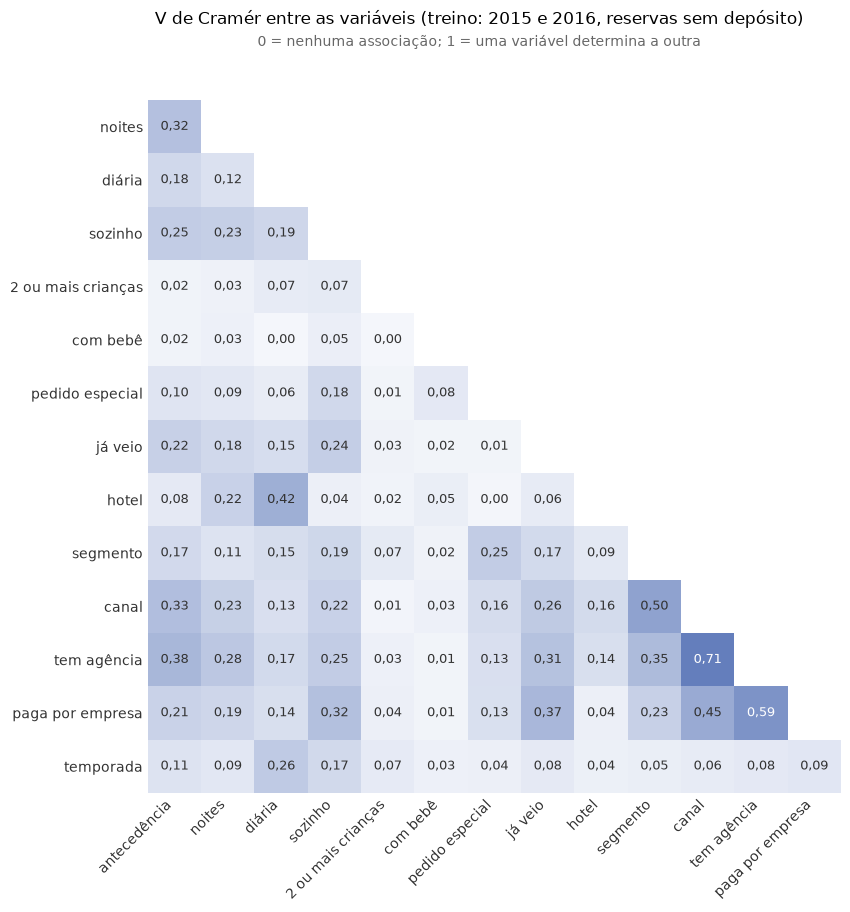

In [3]:
# V de Cramér entre cada par de variáveis (treino)
matriz_v = v_cramer_pares(treino, variaveis)
grafico_v_cramer(matriz_v, nomes=NOMES_VARIAVEIS,
                 titulo='V de Cramér entre as variáveis (treino: 2015 e 2016, reservas sem depósito)',
                 subtitulo='0 = nenhuma associação; 1 = uma variável determina a outra')
plt.show()

**Leitura.**

- **As associações fortes envolvem as candidatas:** canal × tem agência (0,71), tem agência × paga por empresa (0,59), canal × segmento (0,50) e canal × paga por empresa (0,45). A seção 3 confere se isso chega a ser multicolinearidade.
- **A diária se associa ao hotel (0,42)** e, menos, à temporada (0,26): o preço depende de onde e de quando.
- **Entre as demais, as associações são moderadas:** a maior é já veio × paga por empresa (0,37), seguida de antecedência × noites e sozinho × paga por empresa (0,32 cada). Nenhuma chega perto de repetir outra.
- **2 ou mais crianças quase não se associa a nada** (até 0,07): traz informação própria.
- **Com bebê também tem V baixo, mas isso engana:** com 1% das reservas com bebê, o V de Cramér entre duas variáveis sim ou não fica baixo mesmo com relação forte. 84,7% das reservas com bebê fizeram pedido especial (02, seção 3.6), e o stepwise do 05 decide se o bebê acrescenta com o pedido especial no modelo.
- **O V de Cramér olha um par de cada vez.** A multicolinearidade depende de cada variável contra todas as outras juntas: é o que a seção 3 mede.

## 3. Multicolinearidade

O **VIF** (fator de inflação da variância) mede quanto a variância do coeficiente de uma variável aumenta porque ela é explicada pelas outras: 1 quer dizer nenhuma sobreposição; 2,5 quer dizer que a variância fica 2,5 vezes maior. Como várias variáveis têm mais de dois níveis, o notebook usa o **VIF generalizado** (GVIF), que trata cada variável inteira de uma vez. A coluna `vif_equivalente` põe todas na escala do VIF comum.

Os limites mais usados são 5 e 10. A análise adota um limite mais conservador, **2,5**, porque os coeficientes vão para a apresentação, e uma sobreposição moderada já pode inverter um sinal. **Regra:** se uma variável passa de 2,5, sai uma do par a que ela mais se associa (V de Cramér, seção 2); fica a que acrescenta mais ao modelo com todas as outras variáveis (menor BIC).

#### VIF de todas as variáveis juntas

In [4]:
# GVIF com as 14 variáveis juntas (treino)
gvif(treino, variaveis).rename(index=NOMES_VARIAVEIS).round(2)

variavel,gl,GVIF,vif_equivalente
tem agência,1,2.6700,2.6700
canal,1,2.4400,2.4400
paga por empresa,1,1.7600,1.7600
diária,1,1.4200,1.4200
segmento,1,1.4100,1.4100
hotel,1,1.3500,1.3500
sozinho,1,1.2700,1.2700
já veio,1,1.2300,1.2300
noites,2,1.3800,1.1800
antecedência,3,1.5000,1.1500


**Leitura.**

- **Nenhuma variável chega aos limites usuais de 5 e 10:** o maior VIF é 2,67.
- **Só tem agência passa do limite de 2,5 (2,67), e o canal fica logo abaixo (2,44).** O par se associa com V de 0,71 (seção 2): os dois contam quase a mesma história.
- **As outras ficam abaixo de 1,8.** Paga por empresa (1,76), diária (1,42) e segmento (1,41) se sobrepõem um pouco a outras, sem chegar perto do limite.

#### Canal ou tem agência

Os dois primeiros modelos têm as outras 12 variáveis e mais uma do par; o terceiro tem as duas. Quanto menor o BIC, melhor (a regra do 02: se a diferença for de até 2 pontos, decide o AIC).

In [5]:
# qual do par acrescenta mais, com todas as outras variáveis no modelo (treino)
outras = [v for v in variaveis if v not in ('canal', 'tem_agencia')]
formula_outras = 'is_canceled ~ ' + ' + '.join(outras)
comparar_modelos(treino, {
    'outras + canal': formula_outras + ' + canal',
    'outras + tem agência': formula_outras + ' + tem_agencia',
    'outras + canal + tem agência': formula_outras + ' + canal + tem_agencia',
})

modelo,n_coeficientes,AIC,dif_AIC,BIC,dif_BIC
outras + tem agência,17,69110.8000,0,69275,0
outras + canal,17,69118,7.2000,69282.1000,7.2000
outras + canal + tem agência,18,69111.2000,0.4000,69284.5000,9.5000


**Leitura.**

- **Tem agência acrescenta mais que o canal:** o modelo com tem agência tem BIC 7,2 pontos menor que o modelo com o canal.
- **As duas juntas ficam 9,5 pontos de BIC atrás de tem agência sozinha:** o canal não acrescenta ao que tem agência já traz.
- **O canal sai; tem agência fica.**

#### VIF sem o canal

O mesmo cálculo com as 13 variáveis que ficam.

In [6]:
# GVIF sem o canal (treino)
ficam = [v for v in variaveis if v != 'canal']
gvif(treino, ficam).rename(index=NOMES_VARIAVEIS).round(2)

variavel,gl,GVIF,vif_equivalente
tem agência,1,1.9100,1.9100
paga por empresa,1,1.7600,1.7600
diária,1,1.4100,1.4100
hotel,1,1.3400,1.3400
sozinho,1,1.2700,1.2700
já veio,1,1.2300,1.2300
segmento,1,1.2300,1.2300
noites,2,1.3800,1.1700
antecedência,3,1.4900,1.1400
pedido especial,1,1.1200,1.1200


**Leitura.**

- **Sem o canal, todos os VIF ficam abaixo de 2,5:** o maior passa a ser o de tem agência, 1,91.
- **Conclusão: só o canal sai por multicolinearidade.** As outras 13 variáveis vão para o stepwise do `05_modelo.ipynb`.